In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = r"E:\data anaylsis\AI_companion_project\data\ai_companion_dependency_dataset.csv"
df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())
df.info()


Dataset shape: (1000, 30)


,user_id,age,gender,occupation_status,education_level,income_level,relationship_status,living_situation,country_region,ai_chatbot_platform,...,sleep_hours,sleep_quality_score,exercise_hours_weekly,anxiety_score,depression_score,stress_score,self_esteem_score,academic_or_work_performance_change,therapy_attendance,dependency_risk_label
0,U0001,21,Male,Employed Full-Time,High School,Lower-Middle,In a Relationship,With Partner,South America,ChatGPT,...,7.3,9.1,3.3,3.5,3.0,1.0,9.5,Improved,No,Low
1,U0002,34,Male,Student,Graduate,Upper-Middle,Single,Alone,North America,Character.AI,...,7.5,3.5,0.9,4.6,2.4,5.2,4.7,Same,No,Moderate
2,U0003,43,Male,Employed Full-Time,Graduate,Low,Single,Alone,Europe,Character.AI,...,6.8,8.3,7.6,1.0,1.0,3.2,7.2,Improved,No,Low
3,U0004,29,Non-binary,Employed Full-Time,Graduate,Low,Single,With Family,Asia,ChatGPT,...,9.5,8.9,7.4,2.7,1.5,2.6,9.0,Improved,No,Low
4,U0005,25,Female,Student,Graduate,Upper-Middle,In a Relationship,With Roommates,South America,ChatGPT,...,8.5,10.0,6.5,1.0,1.0,1.0,9.9,Improved,No,Low


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 30 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   user_id                              1000 non-null   object 
 1   age                                  1000 non-null   int64  
 2   gender                               1000 non-null   object 
 3   occupation_status                    1000 non-null   object 
 4   education_level                      1000 non-null   object 
 5   income_level                         1000 non-null   object 
 6   relationship_status                  1000 non-null   object 
 7   living_situation                     1000 non-null   object 
 8   country_region                       1000 non-null   object 
 9   ai_chatbot_platform                  1000 non-null   object 
 10  primary_use_case                     1000 non-null   object 
 11  daily_ai_chat_hours            

In [ ]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate user IDs:", df["user_id"].duplicated().sum())

valid_id = df["user_id"].astype(str).str.fullmatch(r"U\d{4}")
print("Invalid user ID formats:", (~valid_id).sum())

expected_ranges = {
    "age": (15, 100),
    "daily_ai_chat_hours": (0, 24),
    "human_social_interaction_hours": (0, 24),
    "social_media_hours_daily": (0, 24),
    "screen_time_total_hours": (0, 24),
    "sleep_hours": (0, 24),
    "loneliness_score": (1, 10),
    "emotional_attachment_score": (1, 10),
    "real_relationship_satisfaction": (1, 10),
    "sleep_quality_score": (1, 10),
    "anxiety_score": (1, 10),
    "depression_score": (1, 10),
    "stress_score": (1, 10),
    "self_esteem_score": (1, 10)
}

for col, (low, high) in expected_ranges.items():
    invalid_count = (~df[col].between(low, high)).sum()
    print(f"{col}: {invalid_count} values outside expected range\n")

object_cols = df.select_dtypes(include="object").columns

for col in object_cols:
    values = df[col].dropna().astype(str)
    spaces = (values != values.str.strip()).sum()
    empty = values.str.strip().eq("").sum()

    if spaces or empty:
        print(f"{col}: {spaces} padded values, {empty} empty strings")


Missing values: 0
Duplicate rows: 0
Duplicate user IDs: 0
Invalid user ID formats: 0
age: 0 values outside expected range

daily_ai_chat_hours: 0 values outside expected range

human_social_interaction_hours: 0 values outside expected range

social_media_hours_daily: 0 values outside expected range

screen_time_total_hours: 0 values outside expected range

sleep_hours: 0 values outside expected range

loneliness_score: 0 values outside expected range

emotional_attachment_score: 0 values outside expected range

real_relationship_satisfaction: 0 values outside expected range

sleep_quality_score: 0 values outside expected range

anxiety_score: 0 values outside expected range

depression_score: 0 values outside expected range

stress_score: 0 values outside expected range

self_esteem_score: 0 values outside expected range



In [ ]:
time_cols = [
    "daily_ai_chat_hours",
    "human_social_interaction_hours",
    "social_media_hours_daily",
    "screen_time_total_hours",
    "sleep_hours",
    "exercise_hours_weekly"
]

display(df[time_cols].describe().T.round(2))

ai_time_issues = df[
    df["daily_ai_chat_hours"] > df["screen_time_total_hours"]
]

overlap_issues = df[
    (df["daily_ai_chat_hours"] + df["social_media_hours_daily"])
    > df["screen_time_total_hours"]
]

daily_time_issues = df[
    (df["sleep_hours"] + df["screen_time_total_hours"]) > 24
]

print("AI chat exceeds total screen time:", len(ai_time_issues))
print("AI chat + social media exceeds screen time:", len(overlap_issues))
print("Sleep + screen time exceeds 24 hours:", len(daily_time_issues))

display(
    overlap_issues[
        [
            "user_id",
            "daily_ai_chat_hours",
            "social_media_hours_daily",
            "screen_time_total_hours"
        ]
    ].sort_values("screen_time_total_hours")
)


,count,mean,std,min,25%,50%,75%,max
daily_ai_chat_hours,1000.0,1.61,1.31,0.0,0.50,1.44,2.53,6.52
human_social_interaction_hours,1000.0,3.99,1.52,0.0,2.95,3.94,5.00,9.75
social_media_hours_daily,1000.0,2.51,1.37,0.0,1.52,2.51,3.42,6.70
screen_time_total_hours,1000.0,6.09,2.63,1.0,4.14,5.77,7.80,14.30
sleep_hours,1000.0,7.04,1.18,3.0,6.20,7.10,7.80,10.00
exercise_hours_weekly,1000.0,4.03,1.95,0.0,2.70,4.00,5.40,9.80


AI chat exceeds total screen time: 0
AI chat + social media exceeds screen time: 22
Sleep + screen time exceeds 24 hours: 0


,user_id,daily_ai_chat_hours,social_media_hours_daily,screen_time_total_hours
334,U0335,0.75,1.29,1.49
427,U0428,0.00,1.92,1.57
828,U0829,0.00,1.93,1.77
595,U0596,0.73,1.94,2.33
122,U0123,1.24,1.55,2.34
247,U0248,0.63,2.37,2.59
368,U0369,0.82,2.98,3.13
895,U0896,1.86,2.21,3.89
957,U0958,3.54,0.70,4.12
62,U0063,2.57,1.65,4.13


In [ ]:
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.drop("user_id")

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print("Unique categories:", df[col].nunique())
    display(
        df[col]
        .value_counts(dropna=False)
        .rename_axis("Category")
        .reset_index(name="Count")
    )



--- gender ---
Unique categories: 4


,Category,Count
0,Male,468
1,Female,452
2,Non-binary,53
3,Prefer not to say,27



--- occupation_status ---
Unique categories: 5


,Category,Count
0,Student,404
1,Employed Full-Time,314
2,Employed Part-Time,126
3,Unemployed,88
4,Freelancer,68



--- education_level ---
Unique categories: 4


,Category,Count
0,Undergraduate,385
1,Graduate,268
2,High School,253
3,Postgraduate,94


... (16 outputs left out)


--- therapy_attendance ---
Unique categories: 2


,Category,Count
0,No,793
1,Yes,207



--- dependency_risk_label ---
Unique categories: 3


,Category,Count
0,Low,519
1,High,295
2,Moderate,186


In [ ]:
numeric_cols = df.select_dtypes(include="number").columns.drop(
    "user_id", errors="ignore"
)

display(df[numeric_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
age,1000.0,29.94,9.03,15.0,22.00,30.00,38.00,44.00
daily_ai_chat_hours,1000.0,1.61,1.31,0.0,0.50,1.44,2.53,6.52
human_social_interaction_hours,1000.0,3.99,1.52,0.0,2.95,3.94,5.00,9.75
social_media_hours_daily,1000.0,2.51,1.37,0.0,1.52,2.51,3.42,6.70
screen_time_total_hours,1000.0,6.09,2.63,1.0,4.14,5.77,7.80,14.30
number_of_close_friends,1000.0,4.10,2.12,0.0,3.00,4.00,5.00,11.00
loneliness_score,1000.0,5.07,2.44,1.0,3.20,5.10,6.80,10.00
emotional_attachment_score,1000.0,4.56,2.47,1.0,2.50,4.50,6.22,10.00
real_relationship_satisfaction,1000.0,6.00,2.32,1.0,4.40,6.05,7.80,10.00
sleep_hours,1000.0,7.04,1.18,3.0,6.20,7.10,7.80,10.00


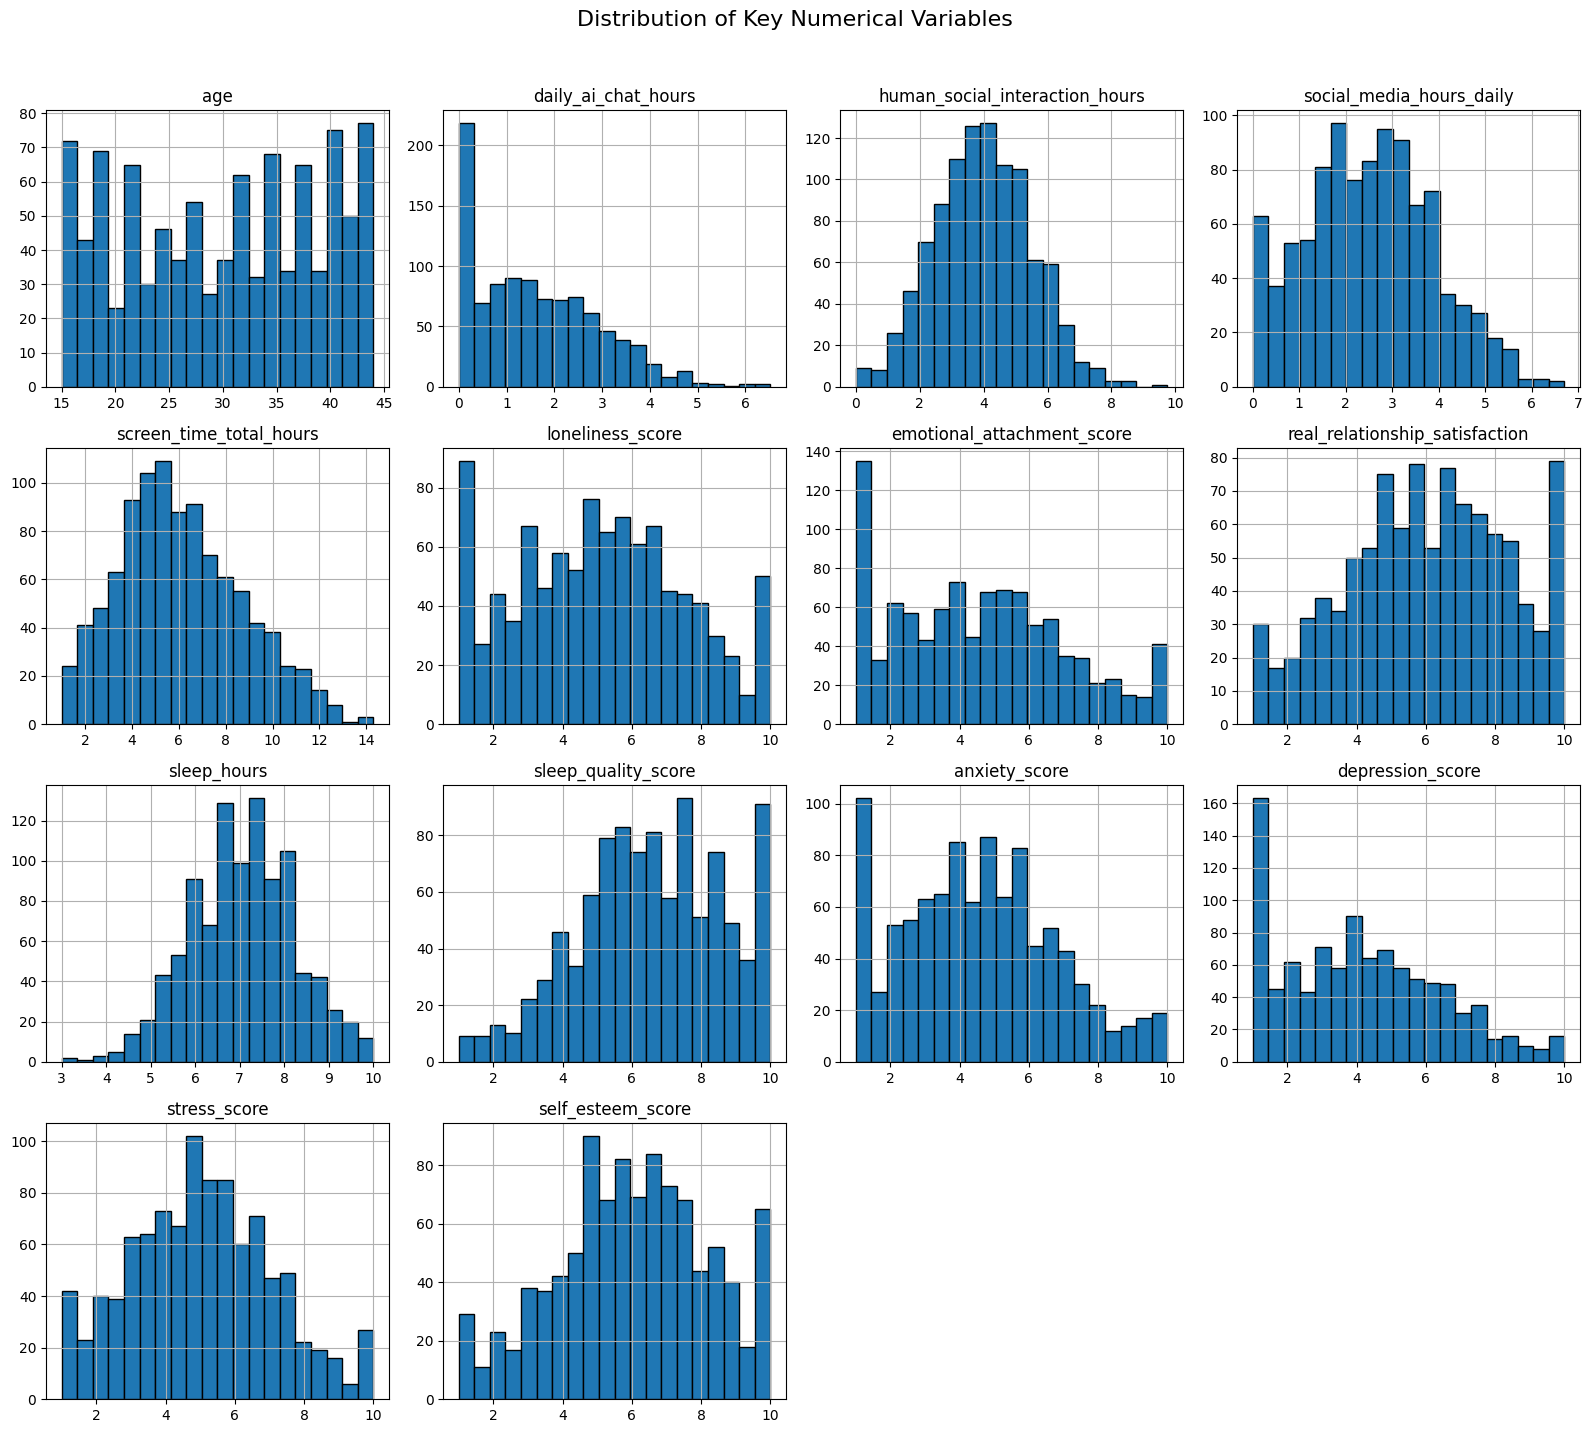

In [ ]:
distribution_cols = [
    "age",
    "daily_ai_chat_hours",
    "human_social_interaction_hours",
    "social_media_hours_daily",
    "screen_time_total_hours",
    "loneliness_score",
    "emotional_attachment_score",
    "real_relationship_satisfaction",
    "sleep_hours",
    "sleep_quality_score",
    "anxiety_score",
    "depression_score",
    "stress_score",
    "self_esteem_score"
]

df[distribution_cols].hist(
    bins=20,
    figsize=(16, 14),
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Key Numerical Variables",
    fontsize=16,
    y=1.02
)
plt.tight_layout()
plt.show()


,Users,Percentage
dependency_risk_label,,
Low,519,51.9
Moderate,186,18.6
High,295,29.5


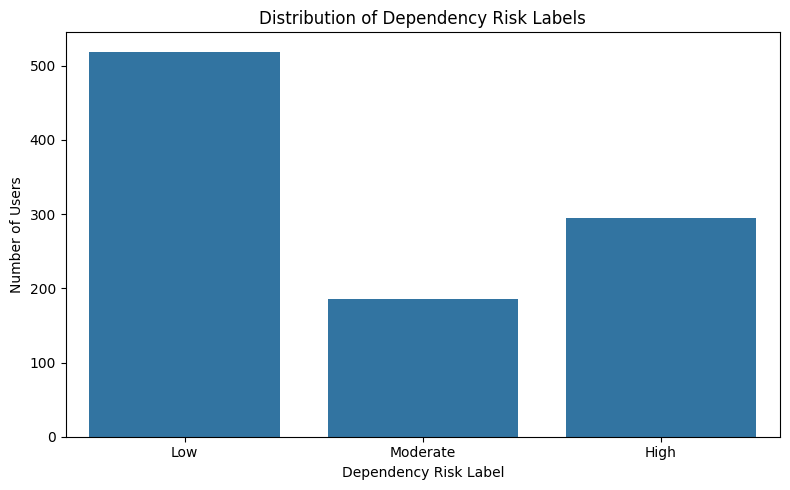

In [ ]:
risk_order = ["Low", "Moderate", "High"]

risk_summary = (
    df["dependency_risk_label"]
    .value_counts()
    .reindex(risk_order, fill_value=0)
    .to_frame(name="Users")
)

risk_summary["Percentage"] = (
    risk_summary["Users"] / len(df) * 100
).round(2)

display(risk_summary)

plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="dependency_risk_label",
    order=risk_order
)
plt.title("Distribution of Dependency Risk Labels")
plt.xlabel("Dependency Risk Label")
plt.ylabel("Number of Users")
plt.tight_layout()
plt.show()


,users,mean_hours,median_hours,q1,q3,max_hours
dependency_risk_label,,,,,,
Low,519,0.74,0.59,0.00,1.25,3.28
Moderate,186,1.84,1.82,1.27,2.37,3.89
High,295,3.00,2.96,2.29,3.66,6.52


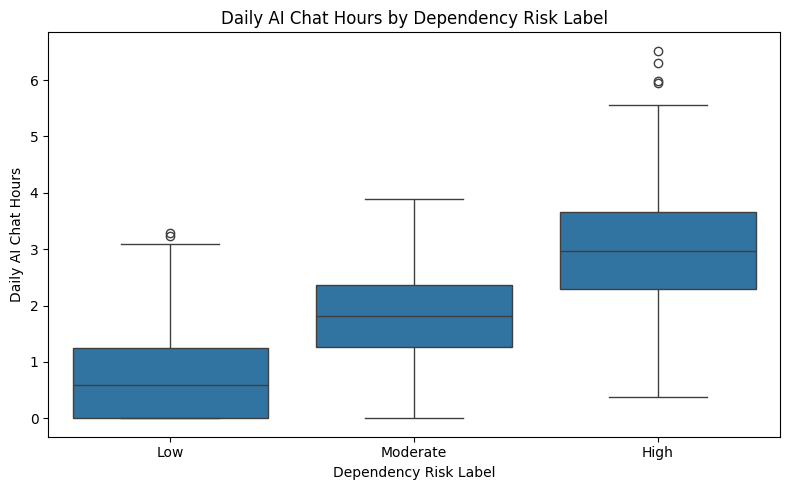

In [ ]:
risk_usage_summary = (
    df.groupby("dependency_risk_label")["daily_ai_chat_hours"]
    .agg(
        users="count",
        mean_hours="mean",
        median_hours="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        max_hours="max"
    )
    .reindex(risk_order)
    .round(2)
)

display(risk_usage_summary)

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="dependency_risk_label",
    y="daily_ai_chat_hours",
    order=risk_order
)
plt.title("Daily AI Chat Hours by Dependency Risk Label")
plt.xlabel("Dependency Risk Label")
plt.ylabel("Daily AI Chat Hours")
plt.tight_layout()
plt.show()


In [ ]:
wellbeing_cols = [
    "loneliness_score",
    "emotional_attachment_score",
    "human_social_interaction_hours",
    "sleep_quality_score",
    "real_relationship_satisfaction",
    "anxiety_score",
    "depression_score",
    "stress_score",
    "self_esteem_score"
]

correlation_summary = (
    df[["daily_ai_chat_hours"] + wellbeing_cols]
    .corr(numeric_only=True)["daily_ai_chat_hours"]
    .drop("daily_ai_chat_hours")
    .sort_values(ascending=False)
    .rename("Correlation with AI Usage")
    .to_frame()
    .round(3)
)

display(correlation_summary)


,Correlation with AI Usage
emotional_attachment_score,0.748
loneliness_score,0.744
depression_score,0.743
anxiety_score,0.713
stress_score,0.666
human_social_interaction_hours,-0.620
real_relationship_satisfaction,-0.688
sleep_quality_score,-0.707
self_esteem_score,-0.713


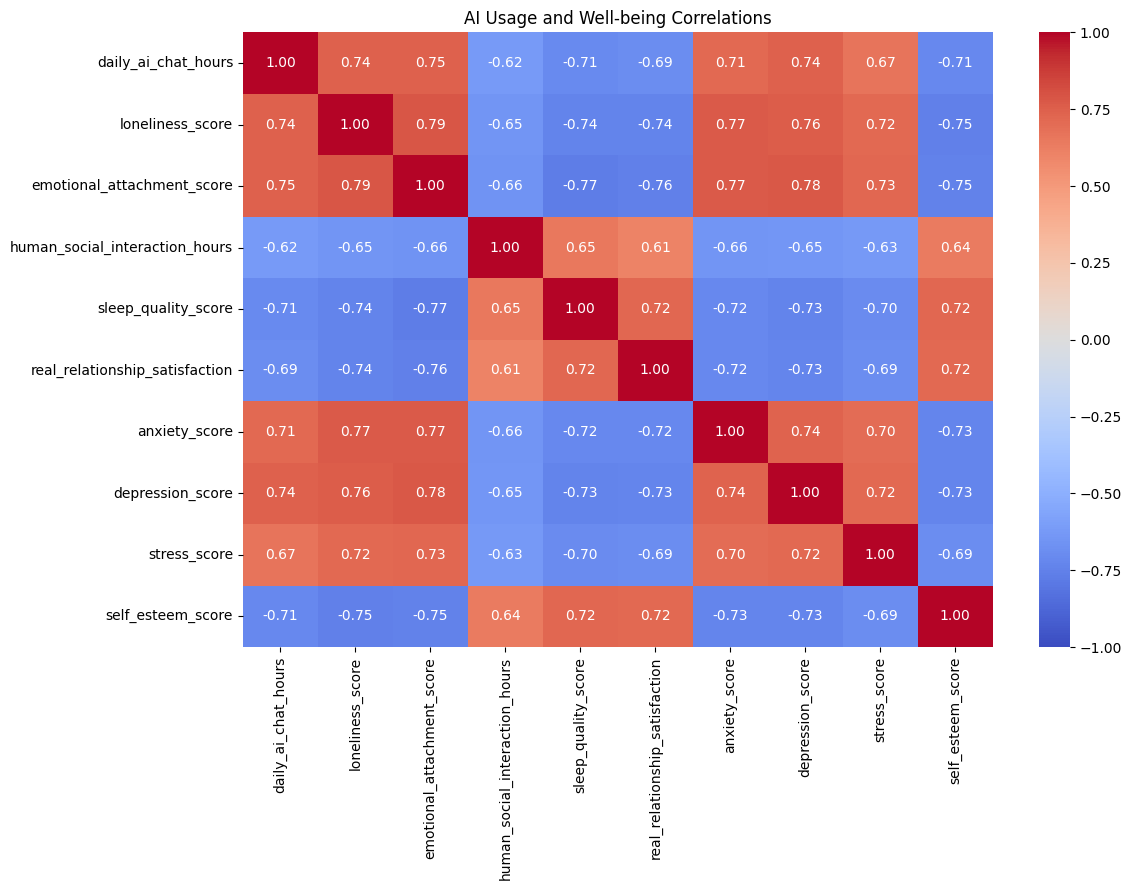

In [ ]:
correlation_matrix = df[
    ["daily_ai_chat_hours"] + wellbeing_cols
].corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("AI Usage and Well-being Correlations")
plt.tight_layout()
plt.show()


,users,mean_hours,median_hours
ai_chatbot_platform,,,
Claude,108,1.70,1.67
ChatGPT,396,1.63,1.45
Replika,149,1.62,1.40
Character.AI,254,1.61,1.44
Other/Multiple,93,1.45,1.16


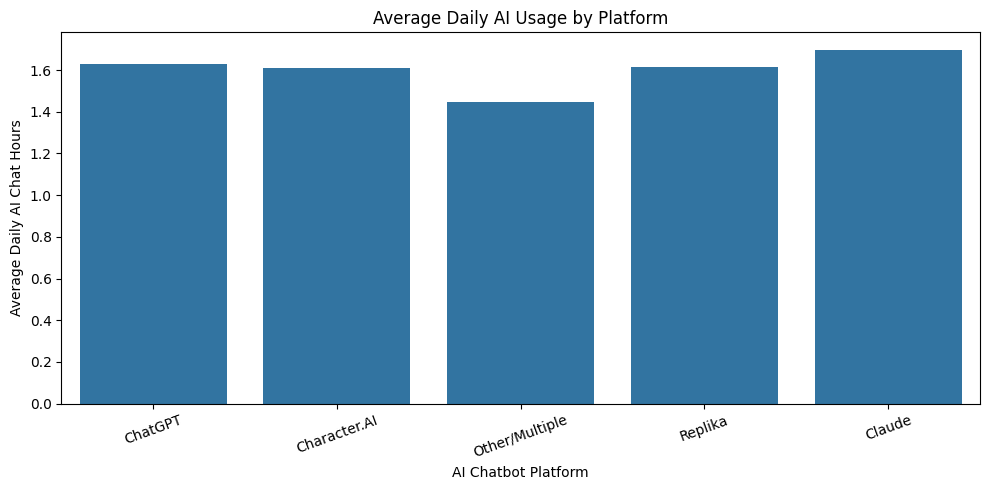

In [ ]:
platform_summary = (
    df.groupby("ai_chatbot_platform")["daily_ai_chat_hours"]
    .agg(
        users="count",
        mean_hours="mean",
        median_hours="median"
    )
    .sort_values("mean_hours", ascending=False)
    .round(2)
)

display(platform_summary)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=df,
    x="ai_chatbot_platform",
    y="daily_ai_chat_hours",
    estimator="mean",
    errorbar=None
)
plt.title("Average Daily AI Usage by Platform")
plt.xlabel("AI Chatbot Platform")
plt.ylabel("Average Daily AI Chat Hours")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


,users,mean_hours,median_hours
primary_use_case,,,
Learning,107,1.82,1.82
Productivity/Work,309,1.72,1.53
Therapy-Substitute,149,1.67,1.50
Entertainment,173,1.53,1.39
Companionship,262,1.43,1.25


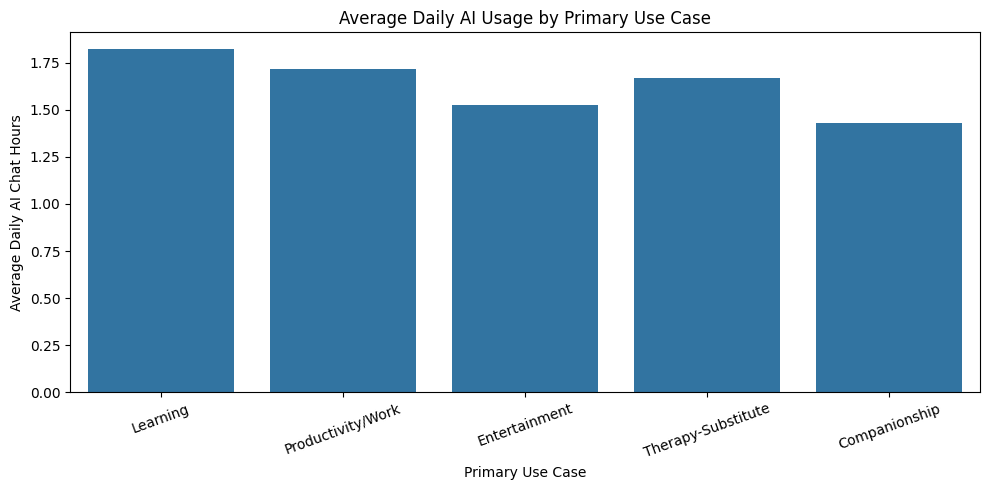

In [ ]:
use_case_summary = (
    df.groupby("primary_use_case")["daily_ai_chat_hours"]
    .agg(
        users="count",
        mean_hours="mean",
        median_hours="median"
    )
    .sort_values("mean_hours", ascending=False)
    .round(2)
)

display(use_case_summary)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=df,
    x="primary_use_case",
    y="daily_ai_chat_hours",
    estimator="mean",
    errorbar=None
)
plt.title("Average Daily AI Usage by Primary Use Case")
plt.xlabel("Primary Use Case")
plt.ylabel("Average Daily AI Chat Hours")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


dependency_risk_label,Low,Moderate,High
ai_chatbot_platform,,,
Character.AI,51.57,18.90,29.53
ChatGPT,51.77,18.94,29.29
Claude,52.78,16.67,30.56
Other/Multiple,50.54,22.58,26.88
Replika,53.02,16.11,30.87


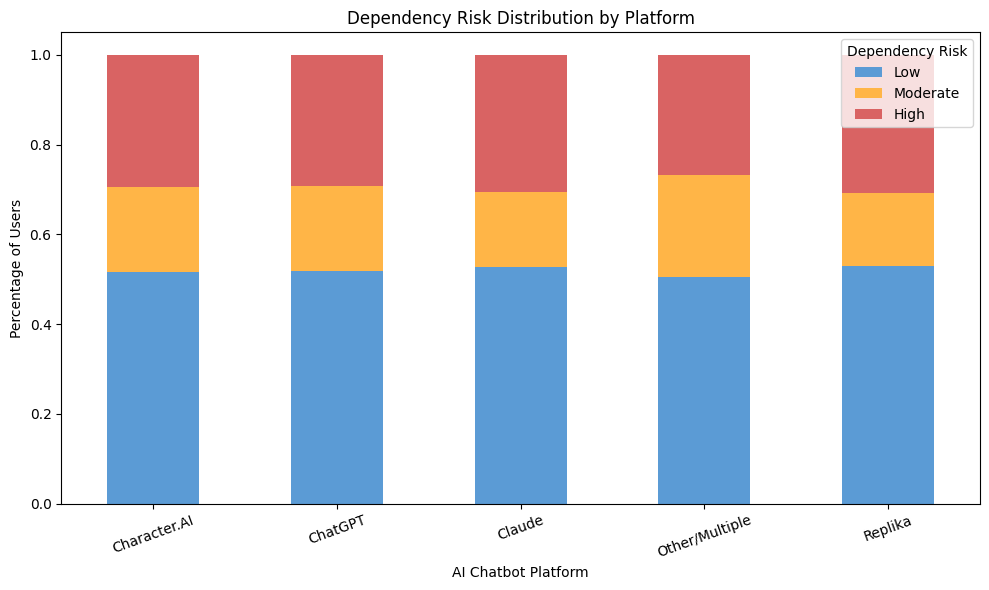

In [ ]:
risk_platform = pd.crosstab(
    df["ai_chatbot_platform"],
    df["dependency_risk_label"],
    normalize="index"
).reindex(columns=["Low", "Moderate", "High"])

display((risk_platform * 100).round(2))

risk_platform.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["#5B9BD5", "#FFB547", "#D96363"]
)

plt.title("Dependency Risk Distribution by Platform")
plt.xlabel("AI Chatbot Platform")
plt.ylabel("Percentage of Users")
plt.legend(title="Dependency Risk")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
